# M06-4 | Is QAT Really Better Than PTQ at Low Bit Widths? A Controlled Experiment at int4

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m06_qat_pipeline/04_qat_vs_ptq_int4.ipynb)

M06-1 showed that at int8, PTQ is already right next to fp32 and QAT has nothing to rescue. This notebook pushes the bit width down to **int4** (activation [-8, 7], weight [-7, 7]) and verifies something that sounds obvious: at low bit widths QAT works better than PTQ.

Be careful: QAT does two things at once, **it trains a few more epochs**, and **it simulates quantization during training**. The test loss may drop simply because of the extra training. So we add two controls:

- **No new data**: the 1024 samples QAT uses are exactly the same set the fp32 model was originally trained on.
- **Control group "retrain, then PTQ"**: retrain the fp32 model (no fake quant) with the same data, lr, and number of epochs, then do PTQ int4.

If the benefit of QAT came only from extra training, the control group should be just as good. Each group runs 5 seeds (the seed only changes the data order during training).

- **A.** Baselines: fp32 and PTQ int4, and the fact that the fp32 model has already memorized the training data.
- **B.** QAT int4 vs retrain-then-PTQ int4.

In [1]:
#| include: false
# When running on Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m06_qat_pipeline")

In [2]:
import copy

import matplotlib.pyplot as plt
import torch
from matplotlib_inline.backend_inline import set_matplotlib_formats

from common.data import calibration_batches, evaluate_loss, make_loader, train, trained_tiny_net
from common.models import example_inputs
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, prepare_qat_pt2e, quiet
from common.qat import INT4_RANGE, freeze_for_eval, qat_quantizer, train_qat
from common.viz import table

quiet()
_ = torch.manual_seed(0)
set_matplotlib_formats("svg")
BLUE, MUTED, GRID = "#2a78d6", "#52514e", "#e6e5e1"

## A. Baselines

`INT4_RANGE` (`common/qat.py`) is the integer range above: XNNPACKQuantizer's config function accepts these four arguments, and the dtype is still int8.
`trained_tiny_net()` trains the fp32 model on the 1024 samples from `make_loader(n=1024, seed=1)`; below we also compute its loss on this training data:

In [3]:
model = trained_tiny_net()
train_data = make_loader(n=1024, seed=1, shuffle=False)  # the fp32 model's training data, also the set QAT will use
test_loader = make_loader(n=1024, seed=2, shuffle=False)


def ptq_int4(m):
    prepared = prepare_pt2e(export_module(copy.deepcopy(m), example_inputs()),
                            get_xnnpack_quantizer(is_per_channel=True, **INT4_RANGE)[0])
    with torch.no_grad():
        for batch in calibration_batches(128):
            prepared(*batch)
    return convert_pt2e(prepared)


ptq = ptq_int4(model)
FP32_LOSS, PTQ_LOSS = evaluate_loss(model, test_loader), evaluate_loss(ptq, test_loader)
table([["fp32", f"{evaluate_loss(model, train_data):.3f}", f"{FP32_LOSS:.3f}"],
       ["PTQ int4", f"{evaluate_loss(ptq, train_data):.3f}", f"{PTQ_LOSS:.3f}"]],
      ["Model", "Loss on training data", "test loss"])

Model,Loss on training data,test loss
fp32,0.006,0.826
PTQ int4,0.054,1.064


In [4]:
assert evaluate_loss(model, train_data) < 0.05 and PTQ_LOSS > FP32_LOSS + 0.1

- The fp32 model's loss on the training data is almost 0, yet its test loss is around 0.8: it has already memorized these 1024 samples. Training on the same data again brings no new information.
- The test loss of PTQ int4 is a good bit higher than fp32; this is the part QAT should win back.

## B. QAT int4 vs Retrain-then-PTQ int4

Both groups use the same recipe: the same 1024 samples, lr 1e-3, 5 epochs, the same set of seeds.

- **QAT int4**: after `prepare_qat_pt2e`, train with `train_qat()` (the loop from M06-1), and evaluate after `freeze_for_eval()`. Evaluation uses the fake quant graph without convert: M06-3 already confirmed the two give the same output.
- **Retrain-then-PTQ int4**: retrain the fp32 model with `common.data.train()` (an ordinary PyTorch training loop), then do PTQ int4. We also record the retrained fp32 itself.

In [5]:
SEEDS = (1, 2, 3, 4, 5)
base = prepare_qat_pt2e(export_module(copy.deepcopy(model), example_inputs(), train=True), qat_quantizer(bits=4))

results = {"QAT int4": [], "Retrained, then PTQ int4": [], "Retrained fp32": []}
for seed in SEEDS:
    qat = freeze_for_eval(train_qat(copy.deepcopy(base), epochs=5, lr=1e-3, seed=seed))
    results["QAT int4"].append(evaluate_loss(qat, test_loader))

    retrained = copy.deepcopy(model).train()
    torch.manual_seed(seed)  # same as train_qat: the seed decides the shuffle order of the data
    train(retrained, make_loader(n=1024, seed=1), epochs=5, lr=1e-3)
    retrained.eval()
    results["Retrained fp32"].append(evaluate_loss(retrained, test_loader))
    results["Retrained, then PTQ int4"].append(evaluate_loss(ptq_int4(retrained), test_loader))

Each row of the figure is one group: the light dots are the test loss of each seed, and the dark short line is the mean of the 5 seeds. The dotted line is fp32 and the dashed line is PTQ int4; further left is better.

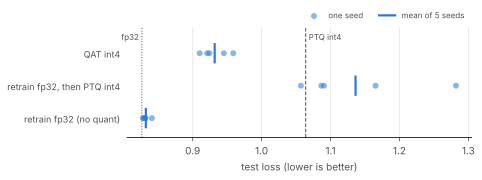

In [6]:
#| code-fold: true
#| code-summary: Plotting code
LABELS = {"QAT int4": "QAT int4", "Retrained, then PTQ int4": "retrain fp32, then PTQ int4", "Retrained fp32": "retrain fp32 (no quant)"}
fig, ax = plt.subplots(figsize=(6.8, 2.6))
for i, (name, vals) in enumerate(results.items()):
    ax.scatter(vals, [i] * len(vals), s=36, color=BLUE, alpha=0.55, linewidths=0,
               label="one seed" if i == 0 else None, zorder=3)
    m = sum(vals) / len(vals)
    ax.plot([m, m], [i - 0.28, i + 0.28], color=BLUE, lw=2.2, label="mean of 5 seeds" if i == 0 else None, zorder=3)
for value, name, style, dx, ha in ((FP32_LOSS, "fp32", ":", -3, "right"), (PTQ_LOSS, "PTQ int4", "--", 3, "left")):
    ax.axvline(value, color=MUTED, lw=1, ls=style)
    ax.annotate(name, (value, -0.5), xytext=(dx, 0), textcoords="offset points", ha=ha, va="center", color=MUTED, fontsize=8)
ax.set_yticks(range(len(results)), [LABELS[n] for n in results], fontsize=9)
ax.set_ylim(len(results) - 0.4, -0.8)
ax.set_xlabel("test loss (lower is better)", color=MUTED)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(colors=MUTED, left=False)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1), ncol=2, frameon=False, labelcolor=MUTED, fontsize=8)
fig.tight_layout()
plt.show()

In [7]:
table([[name, f"{sum(v) / len(v):.3f}", f"{min(v):.3f} ~ {max(v):.3f}"] for name, v in results.items()] +
      [["(reference) original fp32", f"{FP32_LOSS:.3f}", "—"], ["(reference) original PTQ int4", f"{PTQ_LOSS:.3f}", "—"]],
      ["Group", "Mean test loss", "min ~ max (5 seeds)"])

Group,Mean test loss,min ~ max (5 seeds)
QAT int4,0.932,0.910 ~ 0.959
"Retrained, then PTQ int4",1.136,1.057 ~ 1.282
Retrained fp32,0.832,0.828 ~ 0.841
(reference) original fp32,0.826,—
(reference) original PTQ int4,1.064,—


In [8]:
qat, re_ptq, re_fp32 = results["QAT int4"], results["Retrained, then PTQ int4"], results["Retrained fp32"]
wins = sum(q < PTQ_LOSS for q in qat)
print(f"Seeds where QAT int4 beats PTQ int4: {wins} / {len(SEEDS)}")
assert sum(qat) / len(qat) < PTQ_LOSS and max(qat) < min(re_ptq)  # QAT's mean beats PTQ, and every seed beats the control group
assert all(abs(v - FP32_LOSS) < 0.05 for v in re_fp32)  # retraining by itself barely changes fp32

Seeds where QAT int4 beats PTQ int4: 5 / 5


- **QAT int4 is clearly better than PTQ int4**: the mean test loss is much lower, and this is the main benefit of QAT.
- **The benefit comes from quantization adaptation, not extra training**: retraining fp32 with the same data and the same recipe leaves fp32 itself almost unchanged (the training data was memorized long ago), and PTQ int4 afterwards is no better than the original PTQ. Both got the same 5 extra epochs, but only the group that simulates quantization during training won back accuracy.
- **There is fluctuation across seeds**: the seed only changes the data order, yet QAT's test loss spans a range; this time all the seeds printed above beat PTQ, but that is not guaranteed for every training run, so when comparing, run several seeds and look at the mean. The retrain-then-PTQ group fluctuates across seeds too, and how large its spread is relative to QAT's depends on the platform (it was larger on the macOS arm64 run); PTQ is sensitive to small changes in the weights.

## Summary

- At int4, QAT's mean test loss is clearly better than PTQ's.
- QAT uses the same data the fp32 model has already memorized; retraining fp32 with the same recipe and then doing PTQ gives no improvement, so the benefit comes from simulating quantization during training, not from new data or extra training.